# Customer Segmentation Using K-Means

## Introduction

K-Means is an unsupervised learning algorithm that groups customers into clusters based on similarities in their features. It works by assigning each customer to the nearest cluster centroid and repeatedly updating the centroids until the assignments become stable.

K-Means is relatively simple and efficient, but it also has some limitations:

- **The number of clusters (K) must be chosen in advance.** This means we need to test different values before selecting a suitable one.
- **It is sensitive to outliers.** Extreme values can affect the position of the centroids and the resulting clusters.
- **It can be affected by feature scale.** Features with larger ranges may dominate distance calculations, so scaling is usually important. In this project, the provided PCA data is already transformed, so it should not be scaled again.
- **It works best with compact, reasonably separated clusters.** It may not perform as well when clusters have irregular shapes or substantial overlap.
- **Results can depend on initialization.** Using `n_init=10` helps reduce the effect of a poor initial choice of centroids.

Despite these limitations, K-Means is useful for customer segmentation because it is straightforward, computationally efficient, and produces cluster centroids that can help describe customer groups.

## 1. Import Libraries and Load the Data

The clustering will be performed using `customer_pca.csv`, which contains five principal components. The readable customer features in `customer_features.csv` will be used later to interpret the clusters.

**Note:** The PCA data is already transformed. We will use it directly without applying another scaling step.

In [1]:
# Import the libraries used in this notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)

In [2]:
# Upload the two agreed dataset files only.
from google.colab import files
import os
import re

uploaded = files.upload()

# Colab may rename duplicate uploads, for example: customer_pca (2).csv
# Normalize these names so the notebook can still find the two required files.
def normalized_name(filename):
    name = os.path.basename(filename)
    return re.sub(r" \(\d+\)(?=\.csv$)", "", name)

uploaded_names = {normalized_name(name): name for name in uploaded.keys()}
required_files = ["customer_pca.csv", "customer_features.csv"]
missing_files = [name for name in required_files if name not in uploaded_names]

if missing_files:
    raise FileNotFoundError(
        "Please upload only these required files: " + ", ".join(missing_files)
    )

# Read directly from the uploaded file paths, including any Colab duplicate suffix.
pca_file = uploaded_names["customer_pca.csv"]
features_file = uploaded_names["customer_features.csv"]

Z = pd.read_csv(pca_file, index_col="CustomerID")
info = pd.read_csv(features_file, index_col="CustomerID")

# Keep both datasets in exactly the same customer order.
info = info.loc[Z.index]

print("PCA data shape:", Z.shape)
print("Customer features shape:", info.shape)
print("Uploaded files:", pca_file, "and", features_file)


Saving customer_features.csv to customer_features.csv
Saving customer_pca.csv to customer_pca.csv
PCA data shape: (4143, 5)
Customer features shape: (4143, 14)
Uploaded files: customer_pca.csv and customer_features.csv


In [3]:
Z.head()

,PC1,PC2,PC3,PC4,PC5
CustomerID,,,,,
12346,-2.734894,-2.991986,2.132441,0.998034,0.468937
12347,3.589612,2.281717,-1.242719,-0.382392,-0.807583
12348,1.228287,0.845236,-0.985068,-0.459783,0.898431
12349,0.553772,5.872273,1.939445,0.008892,-0.733261
12350,-2.660162,0.845008,0.680010,0.214199,0.409236


In [4]:
Z.shape

(4143, 5)

In [5]:
Z.columns

Index(['PC1', 'PC2', 'PC3', 'PC4', 'PC5'], dtype='object')

## 2. Choosing the Number of Clusters

We test values of K from 2 to 10 using two evaluation methods:

- **Elbow Method:** measures the within-cluster sum of squares (inertia). We look for a point where the decrease in inertia starts to become less noticeable.
- **Silhouette Score:** measures how similar each customer is to its own cluster compared with other clusters. A higher score generally indicates better-separated clusters.

Neither measure should be used alone. We also consider whether the resulting cluster sizes are practical and meaningful.

In [6]:
inertia = []
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    current_labels = model.fit_predict(Z)

    inertia.append(model.inertia_)
    silhouette_scores.append(silhouette_score(Z, current_labels))

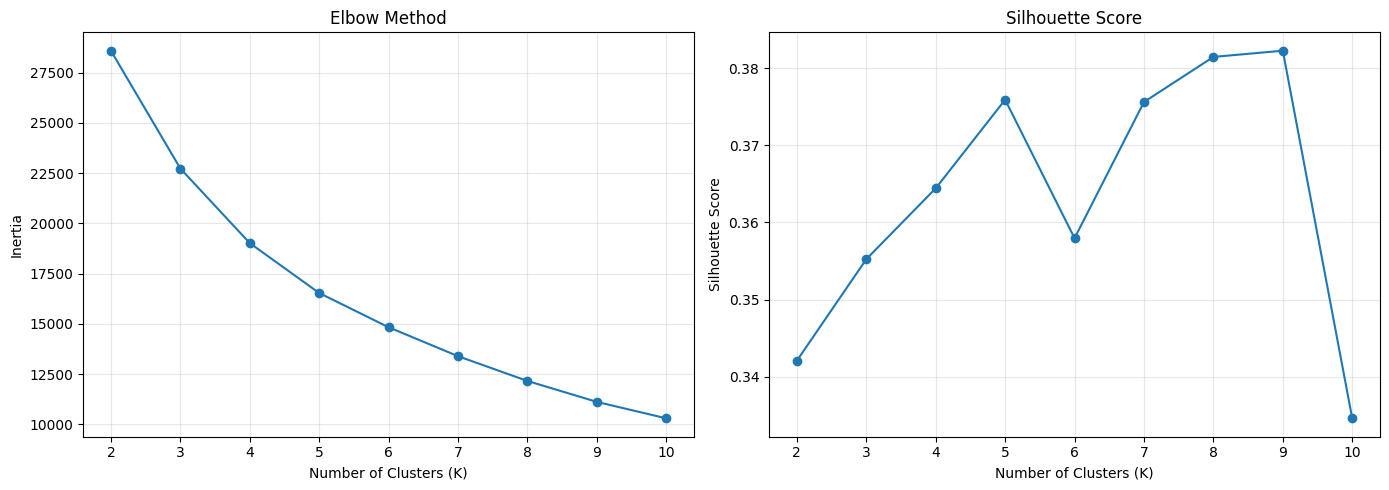

In [7]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(k_values, inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(k_values, silhouette_scores, marker="o")
plt.title("Silhouette Score")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Comparing K = 5, 8, and 9

The plots suggest an elbow around K = 5, while the Silhouette Score is slightly higher at K = 9. To make a more informed choice, we compare K = 5, 8, and 9 using both evaluation scores and cluster sizes.

In [8]:
for k in [5, 8, 9]:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    current_labels = model.fit_predict(Z)

    print(f"K = {k}")
    print("Silhouette Score:", silhouette_score(Z, current_labels))
    print("Davies-Bouldin Score:", davies_bouldin_score(Z, current_labels))
    print("Cluster Sizes:")
    print(pd.Series(current_labels).value_counts().sort_index())
    print("-" * 30)

K = 5
Silhouette Score: 0.37592050065416416
Davies-Bouldin Score: 1.0349902191879434
Cluster Sizes:
0     231
1     782
2    1241
3    1197
4     692
Name: count, dtype: int64
------------------------------
K = 8
Silhouette Score: 0.3814741172732617
Davies-Bouldin Score: 1.0019620278312213
Cluster Sizes:
0     380
1     940
2    1166
3     667
4     241
5      80
6     422
7     247
Name: count, dtype: int64
------------------------------
K = 9
Silhouette Score: 0.38227893188635
Davies-Bouldin Score: 0.9207100779460617
Cluster Sizes:
0     918
1     246
2     240
3     438
4    1166
5      79
6     667
7     380
8       9
Name: count, dtype: int64
------------------------------


### Selected K: 8

K = 9 has slightly better evaluation scores than K = 8. However, it produces a very small cluster containing only 9 customers, which may be less useful for practical customer segmentation.

K = 8 provides a reasonable balance between the evaluation scores and the distribution of customers across clusters. Therefore, we selected **K = 8** for the final K-Means model. This is a practical choice rather than a claim that K = 8 is the best according to every metric.

## 3. Train the Final K-Means Model

We train the final model using 8 clusters, 10 initializations, and a fixed random state to make the results reproducible.

In [9]:
kmeans = KMeans(
    n_clusters=8,
    n_init=10,
    random_state=42
)

labels = kmeans.fit_predict(Z)

### Cluster Sizes

In [10]:
pd.Series(labels, name="Cluster").value_counts().sort_index()

,count
Cluster,
0,380
1,940
2,1166
3,667
4,241
5,80
6,422
7,247


## 4. Visualize the Clusters

The scatter plot shows the customers using PC1 and PC2, with the cluster centroids marked by red X symbols.

**Note:** The model was trained using all five principal components. This plot displays only PC1 and PC2, so it is a two-dimensional view of a clustering process that used five dimensions. Some overlap in this plot does not necessarily mean the clusters overlap in the full PCA space.

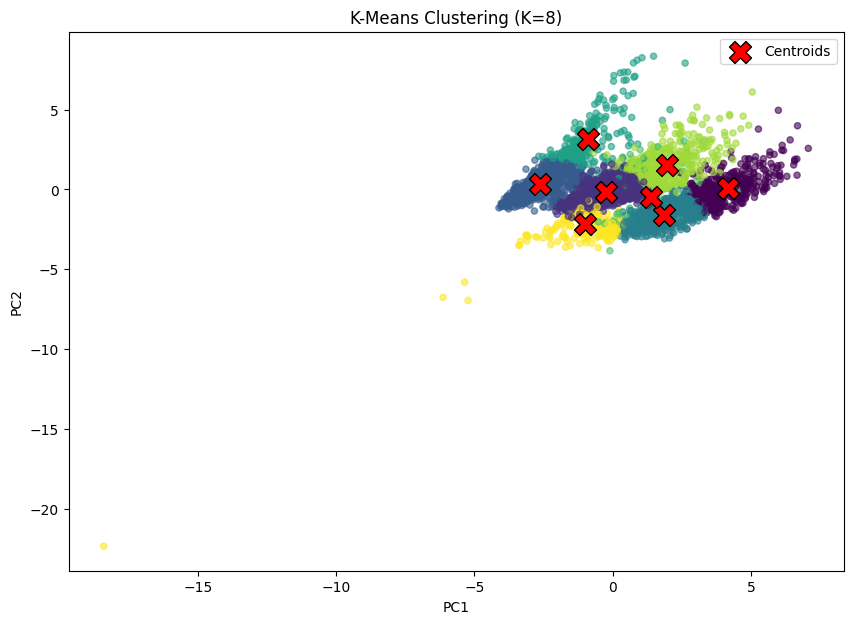

In [11]:
plt.figure(figsize=(10, 7))

plt.scatter(
    Z["PC1"],
    Z["PC2"],
    c=labels,
    cmap="viridis",
    s=20,
    alpha=0.6
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=250,
    c="red",
    edgecolor="black",
    label="Centroids"
)

plt.title("K-Means Clustering (K=8)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

## 5. Evaluate the Final Model

We use two metrics to evaluate the final clustering:

- **Silhouette Score:** higher values generally indicate that customers are closer to their own cluster than to other clusters.
- **Davies-Bouldin Score:** lower values generally indicate more compact and better-separated clusters.

In [12]:
print("Silhouette Score:", silhouette_score(Z, labels))
print("Davies-Bouldin Score:", davies_bouldin_score(Z, labels))

Silhouette Score: 0.3814741172732617
Davies-Bouldin Score: 1.0019620278312213


## 6. Cluster Profiles

The clustering was performed on the PCA components, which are not directly interpretable as customer characteristics. Therefore, we use the original readable features to understand the behavior of customers in each cluster.

The table below shows the median of the numeric features for each cluster. Medians help describe the typical customer in each group and are less affected by extreme values than means.

In [13]:
info["Cluster"] = labels

cluster_profiles = info.groupby("Cluster").median(numeric_only=True)
cluster_profiles

,Recency_Days,N_Invoices,Total_Quantity,Total_Spend,Unique_Products,Avg_Invoice_Value,Avg_Days_Between_Purchases,N_Cancellations,Cancellation_Rate,Monthly_Spend_Mean,Monthly_Spend_Std,Spend_Trend,IsOutlier
Cluster,,,,,,,,,,,,,
0,11.0,11.0,2052.0,3546.615,125.0,342.023125,40.277778,2.0,0.200000,551.929500,305.458779,7.498495,0.0
1,45.0,3.0,319.0,599.155,35.0,200.842500,83.500000,0.0,0.000000,221.481667,68.969174,-1.346470,0.0
2,134.0,1.0,120.0,205.780,14.0,198.575000,0.000000,0.0,0.000000,204.800000,0.000000,0.000000,0.0
3,29.0,6.0,624.0,1124.590,54.0,186.395000,67.500000,1.0,0.250000,280.125000,146.540809,-0.299661,0.0
4,85.0,1.0,440.0,741.260,35.0,655.580000,0.000000,0.0,0.000000,738.960000,0.000000,0.000000,0.0
5,41.0,3.0,653.5,1034.930,45.0,321.361667,17.000000,1.0,0.333333,505.612500,471.612521,-514.310000,0.0
6,23.0,5.0,1200.0,1944.610,91.5,433.003333,59.166667,0.0,0.000000,508.876667,217.739203,8.607511,0.0
7,172.0,2.0,129.0,266.450,14.0,98.975000,0.000000,1.0,0.500000,159.900000,0.000000,0.000000,0.0


### Country Distribution

Country is a categorical feature, so it is not included in the numeric median table. We inspect the most common country in each cluster and the three countries with the highest customer counts.

In [14]:
country_profiles = info.groupby("Cluster")["Country"].agg(
    lambda x: x.mode().iloc[0]
)

country_profiles

,Country
Cluster,
0,United Kingdom
1,United Kingdom
2,United Kingdom
3,United Kingdom
4,United Kingdom
5,United Kingdom
6,United Kingdom
7,United Kingdom


In [15]:
country_counts = (
    info.groupby(["Cluster", "Country"])
    .size()
    .reset_index(name="Count")
    .sort_values(["Cluster", "Count"], ascending=[True, False])
)

country_counts.groupby("Cluster").head(3).reset_index(drop=True)

,Cluster,Country,Count
0,0,United Kingdom,335
1,0,Germany,17
2,0,France,12
3,1,United Kingdom,879
4,1,France,15
5,1,Germany,14
6,2,United Kingdom,1075
7,2,France,25
8,2,Germany,13
9,3,United Kingdom,614


### Initial Cluster Interpretation

Based on the median values, the clusters can be described as follows. These are descriptive labels to make the groups easier to discuss; they are not additional outputs produced by the K-Means algorithm.

| Cluster | Possible description | Main pattern in the median profile |
|---|---|---|
| 0 | Highly active, high-spending customers | Highest purchasing activity, quantity, and total spend |
| 1 | Moderate / lower-activity customers | 3 invoices and lower total spend than the most active groups |
| 2 | Inactive, low-spending customers | High recency, 1 invoice, and low total spend |
| 3 | Regular, moderate-spending customers | 6 invoices and moderate total spend |
| 4 | Occasional, higher-value purchase customers | 1 invoice and relatively high average invoice value |
| 5 | Customers with variable spending | Higher spending variability and a negative median spend trend |
| 6 | Active, high-quantity customers | 5 invoices, high quantity, and high total spend |
| 7 | Low-activity customers with cancellations | Low total spend and a higher median cancellation rate |

The descriptions are based on the available median profiles. They should be interpreted as general patterns rather than assumptions about every customer in a cluster.

The country results show that the United Kingdom is the most common country in every cluster. This suggests that country does not strongly distinguish these clusters in the top-country results; the segmentation appears more useful for describing purchasing behavior.

## 7. K-Means Comparison Using K = 4

This additional section uses K = 4 only to allow a comparison with another clustering approach that was also evaluated using four clusters. It is **not** the final K-Means model selected for this project.

The labels from this comparison are stored in `labels_kmeans_4` and do not replace the final K = 8 labels.

In [16]:
kmeans_4 = KMeans(
    n_clusters=4,
    n_init=10,
    random_state=42
)

labels_kmeans_4 = kmeans_4.fit_predict(Z)

print("K-Means (K=4)")
print("Silhouette:", silhouette_score(Z, labels_kmeans_4))
print("Davies-Bouldin:", davies_bouldin_score(Z, labels_kmeans_4))

print("\nCluster Sizes:")
print(pd.Series(labels_kmeans_4).value_counts().sort_index())

K-Means (K=4)
Silhouette: 0.36442613548503444
Davies-Bouldin: 1.110966036853093

Cluster Sizes:
0     772
1    1219
2    1398
3     754
Name: count, dtype: int64


In [17]:
info_4 = info.drop(columns=["Cluster"], errors="ignore").copy()
info_4["Cluster"] = labels_kmeans_4

profiles_4 = info_4.groupby("Cluster").median(numeric_only=True)
profiles_4

,Recency_Days,N_Invoices,Total_Quantity,Total_Spend,Unique_Products,Avg_Invoice_Value,Avg_Days_Between_Purchases,N_Cancellations,Cancellation_Rate,Monthly_Spend_Mean,Monthly_Spend_Std,Spend_Trend,IsOutlier
Cluster,,,,,,,,,,,,,
0,53.0,4.0,349.5,644.445,31.0,149.862500,48.625000,1.0,0.333333,231.534000,107.261865,0.000000,0.0
1,40.0,3.0,408.0,712.880,41.0,231.316667,76.333333,0.0,0.000000,264.705000,87.767230,-1.016927,0.0
2,127.0,1.0,140.5,242.995,16.0,230.325000,0.000000,0.0,0.000000,241.575000,0.000000,0.000000,0.0
3,15.0,8.0,1684.5,2774.780,108.0,341.216736,46.476190,1.0,0.155870,524.253472,270.130204,6.682256,0.0


## 8. Sensitivity Analysis: Effect of Potential Outliers

K-Means is sensitive to outliers because extreme observations can pull cluster centroids and affect customer assignments. Since this project uses only the two agreed files, we identify **potential outliers within `customer_pca.csv`** using Isolation Forest. We do not use or require a third dataset.

We test several contamination levels (1%, 3%, 5%, and 10%) rather than relying on only one arbitrary percentage. For each level, we:

1. Detect potential outliers using Isolation Forest.
2. Fit K-Means with K = 8 on all customers (baseline).
3. Fit K-Means again after excluding the detected potential outliers.
4. Compare the assignments of the customers retained in both runs using Adjusted Rand Index (ARI).
5. Compare Silhouette and Davies-Bouldin scores on the **same retained customers** in both runs.

This tests how much the potential outliers influence the grouping of the remaining customers. Isolation Forest's flagged customers are treated as *potential* outliers, not confirmed errors or unusual customers. The selected contamination level is an experimental setting, not a fact known in advance.


In [18]:
# Baseline K-Means model on all available customers.
BASE_K = 8
baseline_model = KMeans(n_clusters=BASE_K, n_init=10, random_state=42)
baseline_labels = pd.Series(baseline_model.fit_predict(Z), index=Z.index)

# Test different assumed proportions of potential outliers.
contamination_levels = [0.01, 0.03, 0.05, 0.10]
results = []
outlier_flags_by_level = {}

for contamination in contamination_levels:
    detector = IsolationForest(
        contamination=contamination,
        random_state=42
    )
    flags = detector.fit_predict(Z)
    potential_outliers = pd.Series(flags == -1, index=Z.index)
    retained_mask = ~potential_outliers
    Z_retained = Z.loc[retained_mask]

    # Refit K-Means after excluding the potential outliers.
    clean_model = KMeans(n_clusters=BASE_K, n_init=10, random_state=42)
    clean_labels = pd.Series(
        clean_model.fit_predict(Z_retained),
        index=Z_retained.index
    )

    # Compare the two models on exactly the same retained customers.
    baseline_retained_labels = baseline_labels.loc[retained_mask]
    ari = adjusted_rand_score(baseline_retained_labels, clean_labels)

    # Evaluate both labelings on the same retained PCA observations.
    sil_before = silhouette_score(Z_retained, baseline_retained_labels)
    sil_after = silhouette_score(Z_retained, clean_labels)
    db_before = davies_bouldin_score(Z_retained, baseline_retained_labels)
    db_after = davies_bouldin_score(Z_retained, clean_labels)

    results.append({
        "Assumed outlier %": round(contamination * 100, 1),
        "Detected outliers": int(potential_outliers.sum()),
        "Customers retained": int(retained_mask.sum()),
        "ARI": ari,
        "Silhouette before removal": sil_before,
        "Silhouette after removal": sil_after,
        "Davies-Bouldin before removal": db_before,
        "Davies-Bouldin after removal": db_after
    })
    outlier_flags_by_level[contamination] = potential_outliers

sensitivity_results = pd.DataFrame(results)
sensitivity_results.round(3)


,Assumed outlier %,Detected outliers,Customers retained,ARI,Silhouette before removal,Silhouette after removal,Davies-Bouldin before removal,Davies-Bouldin after removal
0,1.0,42,4101,0.956,0.383,0.378,0.964,0.980
1,3.0,125,4018,0.774,0.383,0.340,0.955,1.088
2,5.0,208,3935,0.756,0.383,0.338,0.952,1.025
3,10.0,415,3728,0.636,0.378,0.345,0.939,1.001


**Observation:**

The results show that increasing the assumed outlier percentage leads to greater changes in customer clustering, as the ARI score decreases from 0.956 at 1% to 0.636 at 10%. However, removing outliers did not consistently improve the Silhouette or Davies-Bouldin scores. This suggests that outliers affect the clustering results, but removing them does not necessarily improve model performance.

### Distribution of Potential Outliers Across the Original K-Means Clusters

For the 5% experiment, this table shows how the potential outliers detected by Isolation Forest are distributed across the original K-Means clusters. It helps identify whether the flagged customers are concentrated in particular clusters or spread across them.


In [21]:
# Use the 5% experiment as a reference for the cluster distribution table.
reference_outlier_flags = outlier_flags_by_level[0.05]

outlier_distribution = pd.DataFrame({
    "Original_Cluster": baseline_labels,
    "Potential_Outlier": reference_outlier_flags.astype(int)
}).groupby("Original_Cluster").agg(
    Customers=("Potential_Outlier", "size"),
    Potential_Outliers=("Potential_Outlier", "sum")
)

outlier_distribution["Outlier_Percentage"] = (
    outlier_distribution["Potential_Outliers"]
    / outlier_distribution["Customers"] * 100
).round(1)

outlier_distribution


,Customers,Potential_Outliers,Outlier_Percentage
Original_Cluster,,,
0,380,24,6.3
1,940,6,0.6
2,1166,0,0.0
3,667,4,0.6
4,241,37,15.4
5,80,59,73.8
6,422,47,11.1
7,247,31,12.6


**Observation:**

The results show that potential outliers are not evenly distributed across the clusters. Cluster 5 has the highest outlier percentage (73.8%), meaning that 59 out of its 80 customers were identified as potential outliers. In contrast, Cluster 2 has no detected potential outliers. This indicates that some clusters are more affected by potential outliers than others.

### How to Interpret the Sensitivity Results

- **ARI close to 1:** the retained customers kept very similar cluster assignments after removing potential outliers.
- **ARI closer to 0:** the grouping of retained customers changed more after removing potential outliers.
- **Silhouette:** higher values generally indicate better-separated clusters.
- **Davies-Bouldin:** lower values generally indicate more compact and better-separated clusters.
- Compare the before/after scores within each contamination level. The comparison uses the same retained customers, so it is more meaningful than comparing scores calculated on different customer sets.

**Important limitations:** Isolation Forest flags potential outliers based on the selected contamination setting; it does not prove that those customers are errors. The results may change with the contamination level. K-Means itself does not label or remove outliers automatically. Use the actual output table to decide whether the effect is small or substantial; do not assume the outliers had a particular effect before seeing the results.


## 9. Strengths, Weaknesses, and When to Use K-Means

### Strengths
- Simple to understand and relatively fast to train, especially on larger datasets.
- Produces clear cluster assignments and centroids that help summarize customer groups.
- Works well when customer groups are reasonably compact and separated.
- Allows us to compare different values of K and select a practical number of customer segments.

### Weaknesses
- The number of clusters (K) must be selected in advance.
- Sensitive to outliers because extreme customers can pull the centroids and affect other assignments.
- Sensitive to initialization and feature scaling; different starting centroids can lead to different results. We used `n_init=10`, a fixed `random_state`, and the provided PCA features without scaling them again.
- Works best with compact, roughly spherical clusters and may struggle with overlapping or irregularly shaped groups.
- Every customer is assigned to a cluster, including unusual customers; K-Means does not identify noise points by itself.

### When to Use K-Means
Use K-Means when the goal is to divide a dataset into a chosen number of practical, interpretable groups, especially when the clusters are expected to be relatively compact. For this project, it provides eight customer segments that can be interpreted using the original purchasing features. If identifying outliers is a main goal, K-Means should be complemented with a separate outlier-detection method, as in the sensitivity experiment above.


## 10. Save the Final Cluster Labels

The final labels are saved from the selected K = 8 model trained on the original `customer_pca.csv` dataset. The K = 4 comparison and the sensitivity experiment do not replace these final labels.

The saved file keeps the same row order as `customer_pca.csv`.

In [20]:
# Save the final K = 8 labels from the original dataset (4,143 customers).
# The K = 4 comparison and outlier sensitivity experiments do not replace these labels.
np.save("labels_kmeans.npy", labels)

print("Saved labels_kmeans.npy")
print("Number of labels:", len(labels))


Saved labels_kmeans.npy
Number of labels: 4143
